# Final Project: Building a Rainfall Prediction Classifier

**Goal:** predict whether it will rain today in the Melbourne area from the day's weather observations.

**Data:** Australian Government Bureau of Meteorology daily weather observations (`weatherAUS`), 2008–2017, filtered to the Melbourne area.

**Contents**
1. Load and explore the data
2. Feature engineering (target definition, location filter, seasons)
3. Exercise 1–4: seasons, features/target, class balance, train/test split
4. Exercise 5–9: preprocessing pipeline and grid search for a Random Forest
5. Exercise 10–14: evaluation (test score, classification report, confusion matrix, feature importances)
6. Exercise 15: replace the model with Logistic Regression and compare

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # newer scikit-learn deprecates the penalty argument
warnings.filterwarnings("ignore", category=UserWarning)

## 1. Load the data

In [2]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/_0eYOqji3unP1tDNKWZMjg/weatherAUS-2.csv"
df = pd.read_csv(url)
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [3]:
df.count()

Date             145460
Location         145460
MinTemp          143975
MaxTemp          144199
Rainfall         142199
Evaporation       82670
Sunshine          75625
WindGustDir      135134
WindGustSpeed    135197
WindDir9am       134894
WindDir3pm       141232
WindSpeed9am     143693
WindSpeed3pm     142398
Humidity9am      142806
Humidity3pm      140953
Pressure9am      130395
Pressure3pm      130432
Cloud9am          89572
Cloud3pm          86102
Temp9am          143693
Temp3pm          141851
RainToday        142199
RainTomorrow     142193
dtype: int64

Several columns have missing values. We drop the incomplete rows and check how much data remains.

In [4]:
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 56420 entries, 6049 to 142302
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           56420 non-null  str    
 1   Location       56420 non-null  str    
 2   MinTemp        56420 non-null  float64
 3   MaxTemp        56420 non-null  float64
 4   Rainfall       56420 non-null  float64
 5   Evaporation    56420 non-null  float64
 6   Sunshine       56420 non-null  float64
 7   WindGustDir    56420 non-null  str    
 8   WindGustSpeed  56420 non-null  float64
 9   WindDir9am     56420 non-null  str    
 10  WindDir3pm     56420 non-null  str    
 11  WindSpeed9am   56420 non-null  float64
 12  WindSpeed3pm   56420 non-null  float64
 13  Humidity9am    56420 non-null  float64
 14  Humidity3pm    56420 non-null  float64
 15  Pressure9am    56420 non-null  float64
 16  Pressure3pm    56420 non-null  float64
 17  Cloud9am       56420 non-null  float64
 18  Cloud3pm       564

**Points to note – data cleaning.** The raw file has **145,460 rows**, and several columns have many missing values (for example `Sunshine` has only 75,625 values and `Evaporation` only 82,670). After `dropna()`, **56,420 complete rows** remain, about 39% of the data. That's still plenty for this model, and it avoids having to impute weather measurements.

In [5]:
df.columns

Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RainTomorrow'],
      dtype='str')

## 2. Feature engineering

### Redefine the target to avoid data leakage

In [6]:
df = df.rename(columns={'RainToday': 'RainYesterday',
                        'RainTomorrow': 'RainToday'})

**Why rename the columns? (avoiding data leakage).**
- The original target, `RainTomorrow`, asks the model to forecast the next day. The way the lab frames the problem, we predict whether it rains **today** from today's observations.
- If we kept `RainToday` as a feature while predicting `RainTomorrow`, the meaning of the features and the target would be mixed up. Renaming them makes the time order explicit:
  - `RainYesterday`: known information, usable as a feature.
  - `RainToday`: what we want to predict.
- **Remaining caution:** some features, such as `Humidity3pm`, `Pressure3pm` and `Cloud3pm`, are measured *during* the same day the rain occurs. In a real deployment, a forecast made in the morning would only have the 9 am values, so a production model should check which measurements are actually available at prediction time.

### Restrict the data to the Melbourne area

In [7]:
df = df[df.Location.isin(['Melbourne', 'MelbourneAirport', 'Watsonia'])]
df.info()

<class 'pandas.DataFrame'>
Index: 7557 entries, 64191 to 80997
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           7557 non-null   str    
 1   Location       7557 non-null   str    
 2   MinTemp        7557 non-null   float64
 3   MaxTemp        7557 non-null   float64
 4   Rainfall       7557 non-null   float64
 5   Evaporation    7557 non-null   float64
 6   Sunshine       7557 non-null   float64
 7   WindGustDir    7557 non-null   str    
 8   WindGustSpeed  7557 non-null   float64
 9   WindDir9am     7557 non-null   str    
 10  WindDir3pm     7557 non-null   str    
 11  WindSpeed9am   7557 non-null   float64
 12  WindSpeed3pm   7557 non-null   float64
 13  Humidity9am    7557 non-null   float64
 14  Humidity3pm    7557 non-null   float64
 15  Pressure9am    7557 non-null   float64
 16  Pressure3pm    7557 non-null   float64
 17  Cloud9am       7557 non-null   float64
 18  Cloud3pm       7557

**Why only Melbourne, Melbourne Airport and Watsonia?** These three stations are close to each other and share the same climate, so they can be treated as one area. Australia covers very different climates, from tropical north to temperate south, and mixing them would make the patterns harder to learn. The filter leaves **7,557 days** of complete records.

## Exercise 1: Map the dates to seasons

In [8]:
def date_to_season(date):
    """Southern Hemisphere seasons."""
    month = date.month
    if month in (12, 1, 2):
        return 'Summer'
    elif month in (3, 4, 5):
        return 'Autumn'
    elif month in (6, 7, 8):
        return 'Winter'
    else:
        return 'Spring'

In [9]:
df['Date'] = pd.to_datetime(df['Date'])

# Apply the function to the 'Date' column
df['Season'] = df['Date'].apply(date_to_season)

df = df.drop(columns=['Date'])
df

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainYesterday,RainToday,Season
64191,MelbourneAirport,11.2,19.9,0.0,5.6,8.8,SW,69.0,W,SW,...,37.0,1005.1,1006.4,7.0,7.0,15.9,18.1,No,Yes,Summer
64192,MelbourneAirport,7.8,17.8,1.2,7.2,12.9,SSE,56.0,SW,SSE,...,43.0,1018.0,1019.3,6.0,7.0,12.5,15.8,Yes,No,Summer
64193,MelbourneAirport,6.3,21.1,0.0,6.2,10.5,SSE,31.0,E,S,...,35.0,1020.8,1017.6,1.0,7.0,13.4,19.6,No,No,Summer
64194,MelbourneAirport,8.1,29.2,0.0,6.4,12.5,SSE,35.0,NE,SSE,...,23.0,1016.2,1012.8,5.0,4.0,16.0,28.2,No,No,Summer
64195,MelbourneAirport,9.7,29.0,0.0,7.4,12.3,SE,33.0,SW,SSE,...,31.0,1011.9,1010.3,6.0,2.0,19.4,27.1,No,No,Summer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80992,Watsonia,3.6,14.5,0.0,2.4,8.8,NNE,41.0,ENE,NNE,...,66.0,1028.4,1025.0,1.0,7.0,5.2,13.8,No,No,Winter
80994,Watsonia,4.8,13.3,0.4,0.6,0.0,NNW,24.0,NE,NNE,...,63.0,1028.5,1025.1,7.0,7.0,5.6,12.4,No,No,Winter
80995,Watsonia,5.6,13.1,0.0,1.6,6.0,NNW,52.0,NE,N,...,67.0,1019.0,1014.0,1.0,7.0,8.8,11.6,No,Yes,Winter
80996,Watsonia,6.9,12.1,3.2,1.8,5.6,SSW,24.0,WNW,SW,...,61.0,1018.7,1017.3,2.0,7.0,7.9,11.0,Yes,No,Winter


**Why seasons instead of dates?** A raw date has thousands of unique values that won't repeat in the future, so the model can't learn from it. The season captures the yearly cycle in 4 categories. Australia is in the Southern Hemisphere, so December–February is summer.

## Exercise 2: Define the feature and target dataframes

In [10]:
X = df.drop(columns='RainToday')
y = df['RainToday']

## Exercise 3: How balanced are the classes?

In [11]:
y.value_counts()

RainToday
No     5766
Yes    1791
Name: count, dtype: int64

In [12]:
y.value_counts(normalize=True)

RainToday
No     0.763001
Yes    0.236999
Name: proportion, dtype: float64

### Answers – Exercise 3

**How often does it rain annually in the Melbourne area?**
It rains on **1,791 of 7,557 days (23.7%)**, which is roughly **87 rainy days per year** (0.237 × 365). This counts only the days with complete records from the three stations, so it's an approximation.

**How accurate would you be if you just assumed it won't rain every day?**
**About 76.3%** (5,766 / 7,557). That's the baseline any model must beat. That "model" would also miss **every** rainy day: recall for "Yes" = 0.

**Is this a balanced dataset?**
**No.** It's moderately imbalanced: about **3.2 "No" days for each "Yes"** day (76% vs 24%). Accuracy alone is therefore misleading, and a model will tend to favour "No".

**Next steps?**
- Split the data with `stratify=y` so training and test sets keep the 76/24 proportion.
- Use stratified cross-validation (`StratifiedKFold`).
- Evaluate with precision, **recall for "Yes"**, F1 and the confusion matrix, not only accuracy.
- If recall for rain is low, try `class_weight='balanced'` or a lower decision threshold.

## Exercise 4: Split the data into training and test sets

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

## Exercise 5: Automatically detect numerical and categorical columns

In [14]:
numeric_features = X_train.select_dtypes(include=['number']).columns.tolist()
# 'exclude' also works with the pandas 3 'str' dtype, where include=['object'] can miss text columns
categorical_features = X_train.select_dtypes(exclude=['number']).columns.tolist()
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Numeric: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Categorical: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainYesterday', 'Season']


### Define separate transformers for both feature types

In [15]:
numeric_transformer = Pipeline(steps=[('scaler', StandardScaler())])
categorical_transformer = Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore'))])

## Exercise 6: Combine the transformers into a single preprocessing column transformer

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

## Exercise 7: Create a pipeline by combining the preprocessing with a Random Forest classifier

In [17]:
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

### Define a parameter grid

In [18]:
param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5]
}

## Exercise 8: Pick a cross-validation method

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

**Why `StratifiedKFold`?** With imbalanced classes, plain K-fold could produce folds with noticeably fewer rainy days, which would make the validation scores unstable. Stratified folds keep about 24% rainy days in every fold. `random_state` makes the folds reproducible.

## Exercise 9: Instantiate and fit GridSearchCV to the pipeline

In [20]:
grid_search = GridSearchCV(pipeline, param_grid, cv=cv, scoring='accuracy', verbose=1)
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [None, 10, ...], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevalu

In [21]:
print("\nBest parameters found: ", grid_search.best_params_)
print("Best cross-validation score: {:.2f}".format(grid_search.best_score_))


Best parameters found:  {'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best cross-validation score: 0.85


**Result.** The best Random Forest uses `max_depth=20`, `min_samples_split=2` and `n_estimators=100`, with a mean **cross-validation accuracy of 0.85**, about 9 points above the 76.3% baseline.

## Exercise 10: Display the model's estimated score on the test set

In [22]:
test_score = grid_search.score(X_test, y_test)
print("Test set score: {:.2f}".format(test_score))

Test set score: 0.84


**Test score: 0.84**, very close to the cross-validation score of 0.85. The model **generalizes well** and isn't overfitting. It beats the "never rains" baseline (0.763) by about 8 points.

## Exercise 11: Get the model predictions from the grid search estimator on the unseen data

In [23]:
y_pred = grid_search.predict(X_test)

## Exercise 12: Print the classification report

In [24]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.95      0.90      1154
         Yes       0.75      0.51      0.61       358

    accuracy                           0.84      1512
   macro avg       0.81      0.73      0.76      1512
weighted avg       0.84      0.84      0.83      1512



## Exercise 13: Plot the confusion matrix

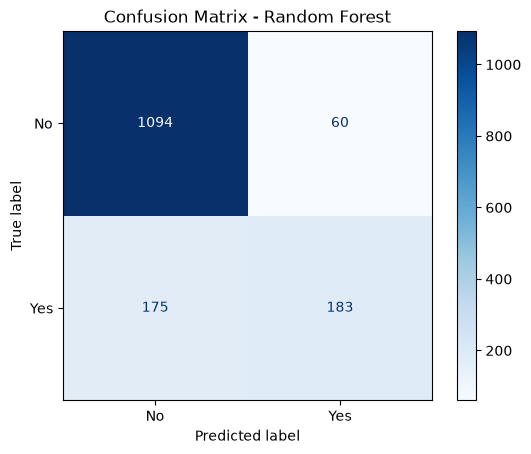

In [25]:
conf_matrix = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=grid_search.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

In [26]:
tn, fp, fn, tp = conf_matrix.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"True positive rate (recall for rain): {tp / (tp + fn):.2f}")

TN=1094  FP=60  FN=175  TP=183
True positive rate (recall for rain): 0.51


### Points to note – Random Forest evaluation

| | Predicted No | Predicted Yes |
|---|---|---|
| **Actual No** | 1,094 (TN) | 60 (FP) |
| **Actual Yes** | 175 (FN) | 183 (TP) |

- **True positive rate (recall for rain) = 183 / 358 = 0.51.** The model catches only about **half of the rainy days**. That's its main weakness.
- **Dry days are predicted very well:** recall 0.95 (1,094 of 1,154).
- **When it predicts rain, it's usually right:** precision for "Yes" is 0.75, with only 60 false alarms.
- **The errors lean toward "No":** 175 missed rainy days vs 60 false alarms, the typical effect of a 3:1 imbalance plus optimizing for accuracy.
- **Overall:** accuracy 0.84 and F1 for rain 0.61. Good at identifying dry days, mediocre at catching rain.

## Exercise 14: Extract the feature importances

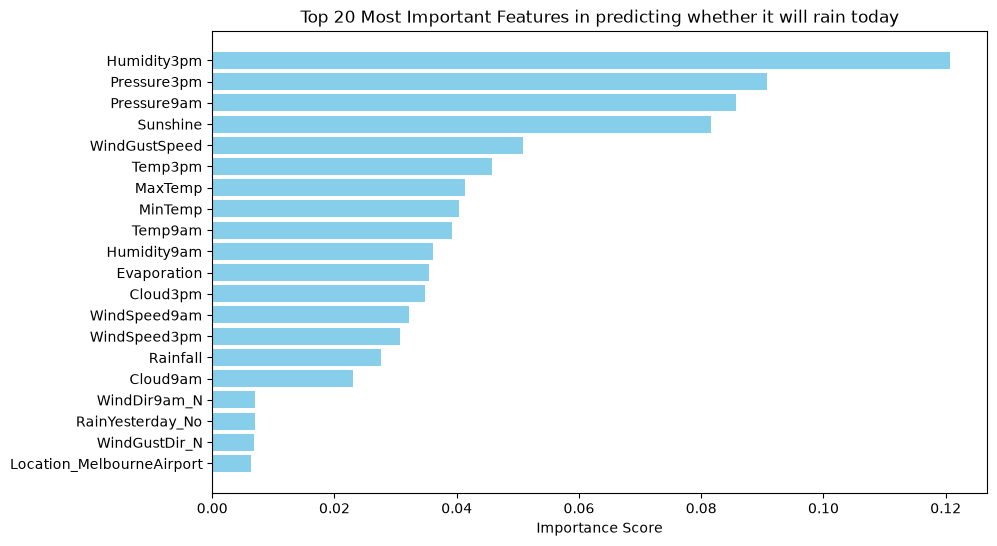

In [27]:
feature_importances = grid_search.best_estimator_['classifier'].feature_importances_

feature_names = numeric_features + list(
    grid_search.best_estimator_['preprocessor']
        .named_transformers_['cat']
        .named_steps['onehot']
        .get_feature_names_out(categorical_features)
)

importance_df = pd.DataFrame({'Feature': feature_names,
                              'Importance': feature_importances}
                             ).sort_values(by='Importance', ascending=False)

N = 20  # top features to show
top_features = importance_df.head(N)

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'], color='skyblue')
plt.gca().invert_yaxis()
plt.title(f'Top {N} Most Important Features in predicting whether it will rain today')
plt.xlabel('Importance Score')
plt.show()

In [28]:
importance_df.head(10)

,Feature,Importance
9,Humidity3pm,0.120752
11,Pressure3pm,0.090827
10,Pressure9am,0.085730
4,Sunshine,0.081560
5,WindGustSpeed,0.050779
15,Temp3pm,0.045733
1,MaxTemp,0.041407
0,MinTemp,0.040418
14,Temp9am,0.039146
8,Humidity9am,0.036119


### Points to note – feature importances

**The most important feature is `Humidity3pm`** (importance ≈ 0.121), followed by `Pressure3pm` (0.091), `Pressure9am` (0.086) and `Sunshine` (0.082).

- These make sense meteorologically: high afternoon humidity, low or falling pressure and little sunshine are classic signs of rain.
- **Is it surprising?** Not really. But `Humidity3pm` and `Pressure3pm` are measured during the same day the rain happens, so part of their importance comes from describing the weather *as it rains*. A forecast made early in the day wouldn't have them.
- **Caution:** impurity-based importance favours continuous features over one-hot columns. Categorical variables such as `Location` or wind direction are split into many 0/1 columns, so each one looks small. Permutation importance would give a fairer comparison.

## Exercise 15: Update the pipeline and the parameter grid (Logistic Regression)

In [29]:
# Replace RandomForestClassifier with LogisticRegression
pipeline.set_params(classifier=LogisticRegression(random_state=42))

# update the model's estimator to use the new pipeline
grid_search.estimator = pipeline

# Define a new grid with Logistic Regression parameters
param_grid = {
    'classifier__solver': ['liblinear'],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__class_weight': [None, 'balanced']
}

grid_search.param_grid = param_grid

# Fit the updated pipeline with LogisticRegression
grid_search.fit(X_train, y_train)

# Make predictions
y_pred = grid_search.predict(X_test)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


### Compare the results to your previous model

Best parameters found:  {'classifier__class_weight': None, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
Test set score: 0.83
              precision    recall  f1-score   support

          No       0.86      0.93      0.89      1154
         Yes       0.69      0.51      0.59       358

    accuracy                           0.83      1512
   macro avg       0.77      0.72      0.74      1512
weighted avg       0.82      0.83      0.82      1512



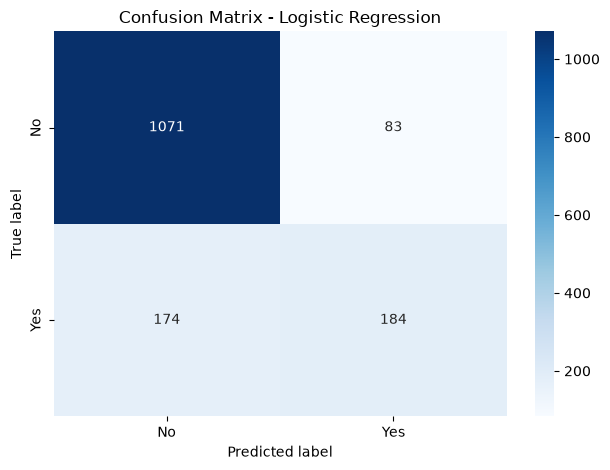

TN=1071  FP=83  FN=174  TP=184
True positive rate (recall for rain): 0.51


In [30]:
print("Best parameters found: ", grid_search.best_params_)
print("Test set score: {:.2f}".format(grid_search.score(X_test, y_test)))
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure()
sns.heatmap(conf_matrix, annot=True, cmap='Blues', fmt='d',
            xticklabels=grid_search.classes_, yticklabels=grid_search.classes_)
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = conf_matrix.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"True positive rate (recall for rain): {tp / (tp + fn):.2f}")

### Points to note – comparing the two models

| Metric (test set) | Random Forest | Logistic Regression |
|---|---|---|
| Accuracy | **0.84** | 0.83 |
| Precision (rain) | **0.75** | 0.69 |
| Recall / true positive rate (rain) | 0.51 | 0.51 |
| F1 (rain) | **0.61** | 0.59 |
| Rainy days caught (TP) | 183 | 184 |
| False alarms (FP) | **60** | 83 |

**Conclusions:**
- **Both models catch the same share of rainy days** (true positive rate 0.51), so both miss about half of them.
- **Random Forest is slightly better overall:** higher accuracy and higher precision for rain, with 23 fewer false alarms. Its non-linear trees capture interactions between humidity, pressure and sunshine that a linear model can't.
- **Logistic Regression is close behind** and is simpler, faster and easier to interpret, since its coefficients can be read directly.
- The grid search chose `class_weight=None` because the scoring was **accuracy**, which rewards predicting the majority class. If catching rain matters more than overall accuracy, the next step is to tune with `scoring='recall'` or `'f1'`, use `class_weight='balanced'`, or lower the decision threshold for "Yes". That would raise the true positive rate at the cost of more false alarms.